## Proposed Dual-Graph AC-SMFAE
Dataset: Lymphoma Dataset

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Load the Lymphoma dataset
file_path = "../data/preprocessed/Lymphoma.csv"
df = pd.read_csv(file_path)

# 2. Separate features and labels
X_raw = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

# 3. Standardize features using Z-score
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 4. Transpose: genes x samples
X = X_scaled.T

# 5. Verify dataset
print("=== Task 1: Lymphoma Dataset Data Setup Summary ===")
print(f"Original DataFrame Shape : {df.shape}")
print(f"Raw Features Shape       : {X_raw.shape}")
print(f"Data Matrix X Shape      : {X.shape} (genes x samples)")
print(f"Labels Vector y Shape    : {y.shape}")
print(f"Number of Classes        : {len(np.unique(y))}")
print(f"Missing Values in X      : {np.isnan(X).sum()}")
print(f"Missing Values in y      : {pd.isna(y).sum()}")

=== Task 1: Lymphoma Dataset Data Setup Summary ===
Original DataFrame Shape : (96, 4027)
Raw Features Shape       : (96, 4026)
Data Matrix X Shape      : (4026, 96) (genes x samples)
Labels Vector y Shape    : (96,)
Number of Classes        : 9
Missing Values in X      : 0
Missing Values in y      : 0


Completed Lymphoma Cancer Microarray Dataset Ingestion & Setup \
Completed Z-score Standardization with shape of 4,026 gene features, 96 samples, 9 unique classes

### Combination A: Single-Graph AC-SMFAE

In [2]:

import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score, pairwise_distances
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment

def sigmoid(u):
    return 1.0 / (1.0 + np.exp(-np.clip(u, -15, 15)))

def accuracy_score_hungarian(y_true, y_pred):
    true_labels, yt = np.unique(y_true, return_inverse=True)
    pred_labels, yp = np.unique(y_pred, return_inverse=True)
    w = np.zeros((len(pred_labels), len(true_labels)), dtype=int)
    np.add.at(w, (yp, yt), 1)
    rows, cols = linear_sum_assignment(w.max() - w)
    return w[rows, cols].sum() / len(yt)

def construct_adaptive_graph(Z_or_X, k=5):
    distances = pairwise_distances(Z_or_X.T, metric="euclidean")
    n = distances.shape[0]
    S = np.zeros((n, n))
    sigma = distances.mean() + 1e-8

    for i in range(n):
        for j in np.argsort(distances[i])[:k+1]:
            if i != j:
                sim = np.exp(-distances[i, j]**2 / (2*sigma**2))
                S[i, j] = max(S[i, j], sim)
                S[j, i] = max(S[j, i], sim)

    D = np.diag(S.sum(axis=1))
    return S, D, D - S

def train_ac_smfae(X, k=5, m=200, alpha=1e-2,
                   beta=1e-4, gamma=1e-3, omega=0.01,
                   lam=1e-4, eta=0, epochs=500,
                   lr=5e-4, update_graph_every=20,
                   L_F=None):
    d, n = X.shape
    np.random.seed(42)

    W1 = np.random.randn(m, d) * np.sqrt(2.0/d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0/m)
    H = np.abs(np.random.randn(m, n)) + 1e-5
    S, D, L = construct_adaptive_graph(X, k)
    loss_history = []

    for epoch in range(1, epochs+1):
        Z = sigmoid(W1 @ X)
        X_hat = W2 @ Z

        if epoch > 1 and epoch % update_graph_every == 0:
            S, D, L = construct_adaptive_graph(Z, k)

        err = X - X_hat
        norms = np.linalg.norm(W1, axis=0) + 1e-8
        d_sig = Z * (1-Z)
        hp_sum = np.sum(d_sig**2, axis=1)
        w1_sq = np.sum(W1**2, axis=1)

        recon = 0.5/n * np.sum(err**2)
        sparse = alpha * np.sum(norms)
        decay = 0.5 * beta * np.sum(W2**2)
        sample_loss = 0.5/n * gamma * np.trace(Z @ L @ Z.T)
        output_loss = 0.5/n * omega * np.sum((H.T @ H - L)**2)
        contractive = lam * np.sum(hp_sum * w1_sq)

        feature_loss = 0.0
        grad_feature = np.zeros_like(W1)
        if L_F is not None:
            LF_W1 = L_F.dot(W1.T).T
            feature_loss = 0.5/n * eta * np.sum(LF_W1 * W1)
            grad_feature = eta/n * LF_W1

        total = (recon + sparse + decay + sample_loss +
                 output_loss + contractive + feature_loss)
        loss_history.append(total)

        grad_W2 = -(err @ Z.T)/n + beta*W2
        dZ = -(W2.T @ err)/n + gamma/n * (Z @ L)
        grad_base = (dZ * d_sig) @ X.T
        grad_sparse = alpha * W1 / norms[None, :]

        A = 2 * d_sig**2 * (1-2*Z)
        grad_cae = lam * (
            2 * hp_sum[:, None] * W1 +
            w1_sq[:, None] * (A @ X.T)
        )

        grad_W1 = np.clip(
            grad_base + grad_sparse + grad_cae + grad_feature, -5, 5
        )
        grad_W2 = np.clip(grad_W2, -5, 5)
        W1 -= lr * grad_W1
        W2 -= lr * grad_W2

        H *= np.sqrt(np.maximum(
            (H @ D) / ((H @ H.T @ H) + H @ S + 1e-8), 1e-8
        ))

        if epoch == 1 or epoch % 100 == 0:
            print(f"Epoch {epoch}/{epochs} | Loss={total:.4f} "
                  f"| Reconstruction={recon:.4f}")

    return W1, W2, H, loss_history

# Train Combination A
W1_comb_a_lym, W2_comb_a_lym, H_comb_a_lym, loss_hist_a_lym = (
    train_ac_smfae(X, eta=0)
)

# Rank genes by encoder-weight magnitude
gene_scores_a = np.linalg.norm(W1_comb_a_lym, axis=0)
ranked_indices_a = np.argsort(gene_scores_a)[::-1]

r_subsets = [2, 10, 20, 50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 20
results_comb_a_lymphoma = {}

print("\nCombination A: Lymphoma Evaluation")
print("Genes | ACC Mean ± STD (%) | NMI Mean ± STD (%)")

for r in r_subsets:
    X_sel = StandardScaler().fit_transform(
        X[ranked_indices_a[:r], :].T
    )
    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        labels = KMeans(
            n_clusters=n_classes, n_init=10, random_state=rep
        ).fit_predict(X_sel)
        acc_list.append(100 * accuracy_score_hungarian(y, labels))
        nmi_list.append(
            100 * normalized_mutual_info_score(y, labels)
        )

    results_comb_a_lymphoma[r] = {
        "ACC_mean": np.mean(acc_list),
        "ACC_std": np.std(acc_list),
        "NMI_mean": np.mean(nmi_list),
        "NMI_std": np.std(nmi_list)
    }
    res = results_comb_a_lymphoma[r]
    print(f"{r:5d} | {res['ACC_mean']:.2f} ± {res['ACC_std']:.2f} "
          f"| {res['NMI_mean']:.2f} ± {res['NMI_std']:.2f}")


Epoch 1/500 | Loss=11121.2093 | Reconstruction=3259.1600
Epoch 100/500 | Loss=1876.0374 | Reconstruction=1862.8623
Epoch 200/500 | Loss=1748.0839 | Reconstruction=1734.9351
Epoch 300/500 | Loss=1632.4747 | Reconstruction=1619.3373
Epoch 400/500 | Loss=1539.2361 | Reconstruction=1526.1070
Epoch 500/500 | Loss=1467.0043 | Reconstruction=1453.8809

Combination A: Lymphoma Evaluation
Genes | ACC Mean ± STD (%) | NMI Mean ± STD (%)
    2 | 37.50 ± 0.00 | 37.92 ± 0.00
   10 | 41.77 ± 4.10 | 47.77 ± 2.23
   20 | 40.83 ± 2.67 | 49.19 ± 2.70
   50 | 50.89 ± 3.80 | 59.49 ± 3.73
  100 | 56.25 ± 4.67 | 64.36 ± 2.23
  150 | 54.69 ± 3.48 | 63.05 ± 2.49
  200 | 56.88 ± 3.43 | 64.21 ± 2.39
  250 | 55.78 ± 4.78 | 64.44 ± 3.56
  300 | 59.01 ± 3.77 | 66.72 ± 3.79


### Combination C: Dual-Graph AC-SMFAE

In [3]:

from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix, diags

def construct_feature_graph_lymphoma(X, k=5):
    # Each row represents one gene across 96 samples
    nn = NearestNeighbors(n_neighbors=k+1, metric="cosine")
    nn.fit(X)
    distances, indices = nn.kneighbors(X)

    valid_distances = distances[:, 1:]
    sigma = valid_distances.mean() + 1e-8
    rows = np.repeat(np.arange(X.shape[0]), k)
    cols = indices[:, 1:].reshape(-1)
    weights = np.exp(
        -(valid_distances.reshape(-1)**2) / (2*sigma**2)
    )

    S = csr_matrix(
        (weights, (rows, cols)), shape=(X.shape[0], X.shape[0])
    )
    S = S.maximum(S.T)
    degrees = np.asarray(S.sum(axis=1)).ravel()
    return diags(degrees) - S

# Construct feature graph: 4026 x 4026, stored sparsely
L_F_lym = construct_feature_graph_lymphoma(X, k=5)
print("Feature graph shape:", L_F_lym.shape)
print("Feature graph storage:", L_F_lym.nnz, "nonzero Laplacian entries")

# Train Combination C
W1_comb_c_lym, W2_comb_c_lym, H_comb_c_lym, loss_hist_c_lym = (
    train_ac_smfae(X, eta=1e-2, L_F=L_F_lym)
)

# Rank genes and evaluate
gene_scores_c = np.linalg.norm(W1_comb_c_lym, axis=0)
ranked_indices_c = np.argsort(gene_scores_c)[::-1]
results_comb_c_lymphoma = {}

print("\nCombination C: Lymphoma Evaluation")
print("Genes | ACC Mean ± STD (%) | NMI Mean ± STD (%)")

for r in r_subsets:
    X_sel = StandardScaler().fit_transform(
        X[ranked_indices_c[:r], :].T
    )
    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        labels = KMeans(
            n_clusters=n_classes, n_init=10, random_state=rep
        ).fit_predict(X_sel)
        acc_list.append(100 * accuracy_score_hungarian(y, labels))
        nmi_list.append(
            100 * normalized_mutual_info_score(y, labels)
        )

    results_comb_c_lymphoma[r] = {
        "ACC_mean": np.mean(acc_list),
        "ACC_std": np.std(acc_list),
        "NMI_mean": np.mean(nmi_list),
        "NMI_std": np.std(nmi_list)
    }
    res = results_comb_c_lymphoma[r]
    print(f"{r:5d} | {res['ACC_mean']:.2f} ± {res['ACC_std']:.2f} "
          f"| {res['NMI_mean']:.2f} ± {res['NMI_std']:.2f}")


Feature graph shape: (4026, 4026)
Feature graph storage: 37176 nonzero Laplacian entries
Epoch 1/500 | Loss=11121.3090 | Reconstruction=3259.1600
Epoch 100/500 | Loss=1876.1354 | Reconstruction=1862.8620
Epoch 200/500 | Loss=1748.1816 | Reconstruction=1734.9352
Epoch 300/500 | Loss=1632.5719 | Reconstruction=1619.3374
Epoch 400/500 | Loss=1539.3329 | Reconstruction=1526.1072
Epoch 500/500 | Loss=1467.1006 | Reconstruction=1453.8812

Combination C: Lymphoma Evaluation
Genes | ACC Mean ± STD (%) | NMI Mean ± STD (%)
    2 | 37.50 ± 0.00 | 37.92 ± 0.00
   10 | 41.77 ± 4.10 | 47.77 ± 2.23
   20 | 40.83 ± 2.67 | 49.19 ± 2.70
   50 | 50.89 ± 3.80 | 59.49 ± 3.73
  100 | 56.25 ± 4.67 | 64.36 ± 2.23
  150 | 54.69 ± 3.48 | 63.05 ± 2.49
  200 | 56.88 ± 3.43 | 64.21 ± 2.39
  250 | 55.78 ± 4.78 | 64.44 ± 3.56
  300 | 59.01 ± 3.77 | 66.72 ± 3.79


### Hyperparameter Tuning Strategy for the Lymphoma Dataset

1. **eta = 0.1 (Feature Graph Weight):** Increases the feature graph weight from `0.01` to `0.1`. This gives the gene relationships more influence during training and may help the encoder learn gene co-expression patterns among the 4,026 genes.

2. **alpha = 1e-3 (Sparsity Weight):** Adjusts the column-wise \(L_{2,1}\) sparsity to select important genes that may help distinguish the nine cancer classes in the Lymphoma dataset.

### Fine-tuned Combination A

In [6]:

# Fine-Tuned Combination A (alpha=0.001, eta=0)

def train_finetuned_single_graph_ac_smfae_lymphoma(
    X, k=5, m=200, alpha=1e-3, beta=1e-4,
    gamma=1e-3, omega=0.01, lam=1e-4,
    lr=5e-4, epochs=500, update_graph_every=20
):
    d, n = X.shape
    np.random.seed(42)

    W1 = np.random.randn(m, d) * np.sqrt(2.0/d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0/m)
    H = np.abs(np.random.randn(m, n)) + 1e-5

    S, D, L = construct_adaptive_graph(X, k=k)
    loss_history = []

    print("Fine-tuned Combination A — Lymphoma")
    print(f"Genes={d}, Samples={n}, alpha={alpha}, eta=0")

    for epoch in range(1, epochs+1):
        Z = sigmoid(W1 @ X)
        X_hat = W2 @ Z

        if epoch > 1 and epoch % update_graph_every == 0:
            S, D, L = construct_adaptive_graph(Z, k=k)

        err = X - X_hat
        norms = np.linalg.norm(W1, axis=0) + 1e-8
        d_sig = Z * (1-Z)
        hp_sum = np.sum(d_sig**2, axis=1)
        w1_sq = np.sum(W1**2, axis=1)

        recon = 0.5/n * np.sum(err**2)
        sparse = alpha * np.sum(norms)
        decay = 0.5 * beta * np.sum(W2**2)
        sample_loss = 0.5/n * gamma * np.trace(Z @ L @ Z.T)
        output_loss = 0.5/n * omega * np.sum((H.T @ H - L)**2)
        contractive = lam * np.sum(hp_sum * w1_sq)

        total = recon + sparse + decay + sample_loss + output_loss + contractive
        loss_history.append(total)

        grad_W2 = -(err @ Z.T)/n + beta*W2
        dZ = -(W2.T @ err)/n + gamma/n * (Z @ L)
        grad_base = (dZ * d_sig) @ X.T
        grad_sparse = alpha * W1 / norms[None, :]

        A = 2*d_sig**2 * (1-2*Z)
        grad_cae = lam * (
            2*hp_sum[:, None]*W1 + w1_sq[:, None]*(A @ X.T)
        )

        grad_W1 = np.clip(grad_base + grad_sparse + grad_cae, -5, 5)
        grad_W2 = np.clip(grad_W2, -5, 5)

        W1 -= lr*grad_W1
        W2 -= lr*grad_W2

        H *= np.sqrt(np.maximum(
            (H @ D) / ((H @ H.T @ H) + H @ S + 1e-8), 1e-8
        ))

        if epoch == 1 or epoch % 100 == 0:
            print(f"Epoch {epoch}/{epochs} | Total={total:.4f} "
                  f"| Reconstruction={recon:.4f}")

    return W1, W2, H, loss_history


# Train the model
W1_ft_a_lym, W2_ft_a_lym, H_ft_a_lym, loss_hist_ft_a_lym = (
    train_finetuned_single_graph_ac_smfae_lymphoma(X)
)

# Rank genes
gene_scores_ft_a = np.linalg.norm(W1_ft_a_lym, axis=0)
ranked_indices_ft_a = np.argsort(gene_scores_ft_a)[::-1]

# Evaluate clustering
r_subsets = [2, 10, 20, 50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 20
results_ft_comb_a_lymphoma = {}

print("\nFine-tuned Combination A Evaluation")
print("Genes | ACC Mean ± STD (%) | NMI Mean ± STD (%)")

for r in r_subsets:
    X_sel = StandardScaler().fit_transform(
        X[ranked_indices_ft_a[:r], :].T
    )
    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        labels = KMeans(
            n_clusters=n_classes, n_init=10, random_state=rep
        ).fit_predict(X_sel)

        acc_list.append(100*accuracy_score_hungarian(y, labels))
        nmi_list.append(
            100*normalized_mutual_info_score(y, labels)
        )

    results_ft_comb_a_lymphoma[r] = {
        "ACC_mean": np.mean(acc_list),
        "ACC_std": np.std(acc_list),
        "NMI_mean": np.mean(nmi_list),
        "NMI_std": np.std(nmi_list)
    }

    res = results_ft_comb_a_lymphoma[r]
    print(f"{r:5d} | {res['ACC_mean']:.2f} ± {res['ACC_std']:.2f} "
          f"| {res['NMI_mean']:.2f} ± {res['NMI_std']:.2f}")


Fine-tuned Combination A — Lymphoma
Genes=4026, Samples=96, alpha=0.001, eta=0
Epoch 1/500 | Total=11109.7978 | Reconstruction=3259.1600
Epoch 100/500 | Total=1864.7349 | Reconstruction=1862.8795
Epoch 200/500 | Total=1736.7558 | Reconstruction=1734.9202
Epoch 300/500 | Total=1621.1483 | Reconstruction=1619.3205
Epoch 400/500 | Total=1527.9078 | Reconstruction=1526.0845
Epoch 500/500 | Total=1455.6698 | Reconstruction=1453.8483

Fine-tuned Combination A Evaluation
Genes | ACC Mean ± STD (%) | NMI Mean ± STD (%)
    2 | 37.50 ± 0.00 | 37.92 ± 0.00
   10 | 41.77 ± 4.10 | 47.77 ± 2.23
   20 | 40.83 ± 2.67 | 49.19 ± 2.70
   50 | 50.89 ± 3.80 | 59.49 ± 3.73
  100 | 56.25 ± 4.67 | 64.36 ± 2.23
  150 | 55.05 ± 3.54 | 63.74 ± 2.70
  200 | 56.88 ± 3.43 | 64.21 ± 2.39
  250 | 55.78 ± 4.78 | 64.44 ± 3.56
  300 | 59.01 ± 3.77 | 66.72 ± 3.79


### Fine-tuned Combination C

In [5]:


# Uses the existing sparse feature graph L_F_lym

W1_ft_lym, W2_ft_lym, H_ft_lym, loss_hist_ft_lym = train_ac_smfae(
    X,
    k=5,
    m=200,
    alpha=1e-3,
    beta=1e-4,
    gamma=1e-3,
    omega=0.01,
    lam=1e-4,
    eta=0.1,
    lr=5e-4,
    epochs=500,
    L_F=L_F_lym
)

# Rank genes by encoder weights
gene_scores_ft = np.linalg.norm(W1_ft_lym, axis=0)
ranked_indices_ft = np.argsort(gene_scores_ft)[::-1]

# Evaluate clustering
results_ft_comb_c_lymphoma = {}

print("\nFine-tuned Combination C — Lymphoma")
print("Genes | ACC Mean ± STD (%) | NMI Mean ± STD (%)")

for r in r_subsets:
    X_sel = StandardScaler().fit_transform(
        X[ranked_indices_ft[:r], :].T
    )
    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        labels = KMeans(
            n_clusters=n_classes, n_init=10, random_state=rep
        ).fit_predict(X_sel)

        acc_list.append(
            100 * accuracy_score_hungarian(y, labels)
        )
        nmi_list.append(
            100 * normalized_mutual_info_score(y, labels)
        )

    results_ft_comb_c_lymphoma[r] = {
        "ACC_mean": np.mean(acc_list),
        "ACC_std": np.std(acc_list),
        "NMI_mean": np.mean(nmi_list),
        "NMI_std": np.std(nmi_list)
    }

    res = results_ft_comb_c_lymphoma[r]
    print(
        f"{r:5d} | {res['ACC_mean']:.2f} ± {res['ACC_std']:.2f} "
        f"| {res['NMI_mean']:.2f} ± {res['NMI_std']:.2f}"
    )


Epoch 1/500 | Loss=11110.7946 | Reconstruction=3259.1600
Epoch 100/500 | Loss=1865.7195 | Reconstruction=1862.8768
Epoch 200/500 | Loss=1737.7423 | Reconstruction=1734.9205
Epoch 300/500 | Loss=1622.1350 | Reconstruction=1619.3215
Epoch 400/500 | Loss=1528.8951 | Reconstruction=1526.0865
Epoch 500/500 | Loss=1456.6576 | Reconstruction=1453.8512

Fine-tuned Combination C — Lymphoma
Genes | ACC Mean ± STD (%) | NMI Mean ± STD (%)
    2 | 37.50 ± 0.00 | 37.92 ± 0.00
   10 | 41.77 ± 4.10 | 47.77 ± 2.23
   20 | 40.83 ± 2.67 | 49.19 ± 2.70
   50 | 49.84 ± 4.04 | 58.55 ± 3.30
  100 | 56.61 ± 4.18 | 65.08 ± 3.19
  150 | 54.38 ± 4.56 | 63.31 ± 3.33
  200 | 54.95 ± 3.78 | 63.99 ± 2.43
  250 | 57.66 ± 4.64 | 65.32 ± 3.49
  300 | 57.14 ± 4.57 | 65.12 ± 1.91


### Comparison Plot

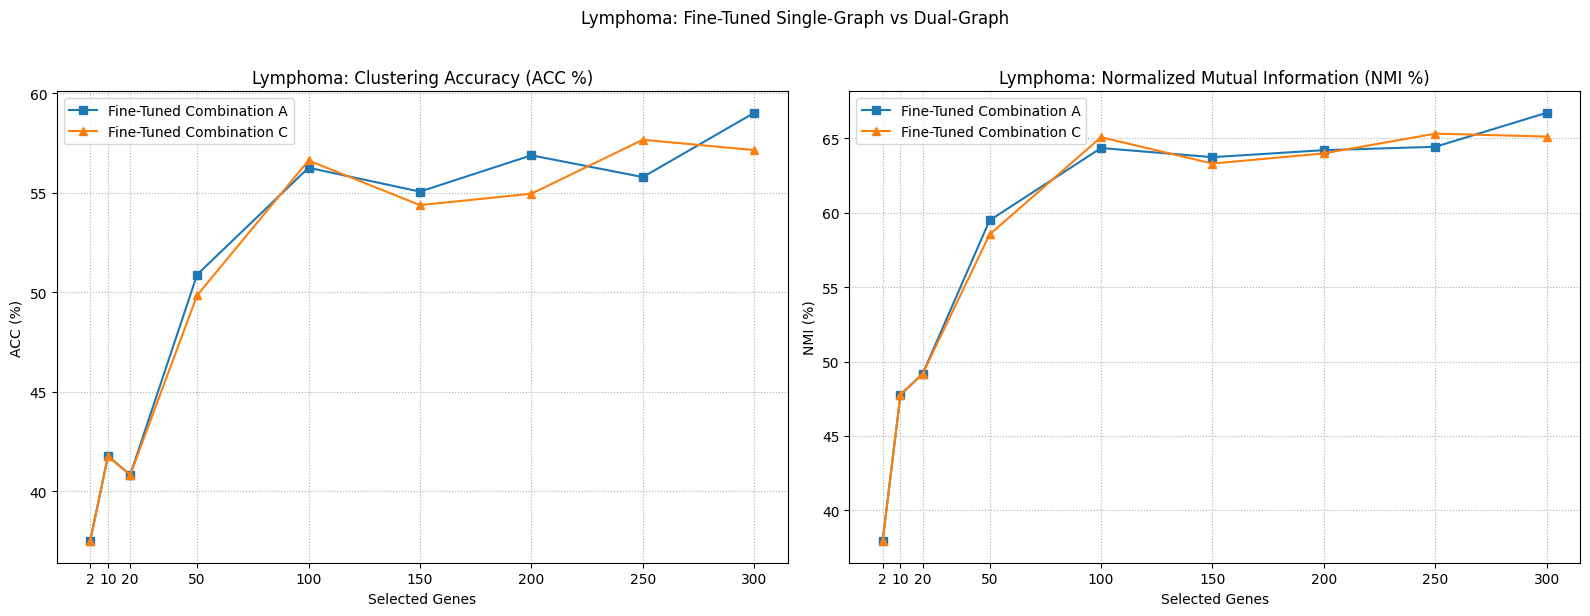

In [7]:

import matplotlib.pyplot as plt

active_r_subsets = sorted(results_ft_comb_a_lymphoma.keys())

acc_ft_a = [results_ft_comb_a_lymphoma[r]["ACC_mean"] for r in active_r_subsets]
nmi_ft_a = [results_ft_comb_a_lymphoma[r]["NMI_mean"] for r in active_r_subsets]

acc_ft_c = [results_ft_comb_c_lymphoma[r]["ACC_mean"] for r in active_r_subsets]
nmi_ft_c = [results_ft_comb_c_lymphoma[r]["NMI_mean"] for r in active_r_subsets]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(active_r_subsets, acc_ft_a, marker="s",
         label="Fine-Tuned Combination A")
ax1.plot(active_r_subsets, acc_ft_c, marker="^",
         label="Fine-Tuned Combination C")
ax1.set_title("Lymphoma: Clustering Accuracy (ACC %)")
ax1.set_xlabel("Selected Genes")
ax1.set_ylabel("ACC (%)")
ax1.set_xticks(active_r_subsets)
ax1.grid(True, linestyle=":")
ax1.legend()

ax2.plot(active_r_subsets, nmi_ft_a, marker="s",
         label="Fine-Tuned Combination A")
ax2.plot(active_r_subsets, nmi_ft_c, marker="^",
         label="Fine-Tuned Combination C")
ax2.set_title("Lymphoma: Normalized Mutual Information (NMI %)")
ax2.set_xlabel("Selected Genes")
ax2.set_ylabel("NMI (%)")
ax2.set_xticks(active_r_subsets)
ax2.grid(True, linestyle=":")
ax2.legend()

fig.suptitle("Lymphoma: Fine-Tuned Single-Graph vs Dual-Graph", y=1.02)
plt.tight_layout()
plt.show()


In [8]:

import os

figures_dir = "../reports/figures"
os.makedirs(figures_dir, exist_ok=True)

fig_path = os.path.join(
    figures_dir, "Lymphoma_All_Combinations_Comparison.png"
)

fig.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.close(fig)

print("Plot saved to:", fig_path)
print("File exists:", os.path.exists(fig_path))


Plot saved to: ../reports/figures\Lymphoma_All_Combinations_Comparison.png
File exists: True


In [9]:

import os
import pandas as pd

results_dir = "../reports/results"
os.makedirs(results_dir, exist_ok=True)
csv_file_path = os.path.join(results_dir, "accuracy_nmi.csv")

experiment_configs = {
    "Single-Graph AC-SMFAE (Fine-Tuned)": (
        results_ft_comb_a_lymphoma, 0.0
    ),
    "Dual-Graph AC-SMFAE (Fine-Tuned Proposed)": (
        results_ft_comb_c_lymphoma, 0.1
    )
}

new_rows = []

for method, (result_dict, eta_value) in experiment_configs.items():
    for r, res in result_dict.items():
        new_rows.append({
            "Method": method,
            "Dataset": "Lymphoma",
            "Num_Features": r,
            "ACC": res["ACC_mean"],
            "NMI": res["NMI_mean"],
            "Num_Samples": 96,
            "Num_Original_Features": 4026,
            "Num_Classes": 9,
            "Num_Selected_Features": r,
            "Hidden_Dimension": 200,
            "Alpha": 1e-3,
            "Beta": 1e-4,
            "Gamma": 1e-3,
            "Omega": 0.01,
            "Lambda": 1e-4,
            "Eta": eta_value,
            "ACC_Mean": res["ACC_mean"],
            "ACC_STD": res["ACC_std"],
            "NMI_Mean": res["NMI_mean"],
            "NMI_STD": res["NMI_std"],
            "Learning_Rate": 5e-4,
            "Epochs": 500,
            "KNN": 5,
            "Repetitions": 20
        })

df_lym_dynamic = pd.DataFrame(new_rows)

if os.path.exists(csv_file_path):
    existing_df = pd.read_csv(csv_file_path)

    if "Dataset" not in existing_df.columns:
        raise ValueError(
            "Existing CSV has no Dataset column. "
            "Check the file before replacing it."
        )

    preserved_df = existing_df[
        existing_df["Dataset"].astype(str).str.upper() != "LYMPHOMA"
    ]

    combined_df = pd.concat(
        [preserved_df, df_lym_dynamic],
        ignore_index=True,
        sort=False
    )
else:
    combined_df = df_lym_dynamic

combined_df.to_csv(csv_file_path, index=False)

print("CSV saved to:", csv_file_path)
print("Total rows:", len(combined_df))
print("\nDataset row counts:")
print(combined_df["Dataset"].value_counts())

print("\nLymphoma rows:", 
      len(combined_df[combined_df["Dataset"] == "Lymphoma"]))


CSV saved to: ../reports/results\accuracy_nmi.csv
Total rows: 128

Dataset row counts:
Dataset
ORL         42
Yale        27
Leukemia    26
Lymphoma    18
Colon        9
Lukemia      6
Name: count, dtype: int64

Lymphoma rows: 18


### Lymphoma Experiment Results Analysis

- **Combination A (Fine-Tuned, `alpha=0.001`):** The best result was obtained with 300 genes, achieving **59.01% ± 3.77% ACC** and **66.72% ± 3.79% NMI**.
- **Combination C (Fine-Tuned, `alpha=0.001`, `eta=0.1`):** Using 250 genes, the model achieved **57.66% ± 4.64% ACC** and **65.32% ± 3.49% NMI**.
- **Effect of `eta = 0.1`:** For the 250-gene subset, Combination C improved ACC from **55.78% to 57.66%** and NMI from **64.44% to 65.32%**. This suggests that increasing the feature graph weight helped clustering performance in this experiment.